# HD 137010 b – circular fit vs. the authors' posterior

Redo of the transit fit in Venner et al. (2026, Sec. 3.4), with what we know now:
- prior $p(P) \propto P^{-8/3}$ (log-uniform × Kipping 2018 $P^{-5/3}$), no upper cut – read off their samples in 03, Sec. 6
- sample in $\ln v$, $v = (a/R_*)/P$, instead of $P$ – same variable as the shape fit in 03, Sec. 5
- compare full distributions with their samples (`posteriors.csv`), not only the Table 2 numbers

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import batman
import emcee

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

# K2 detrended flux, time in BKJD = BJD - 2454833
t_all, _, f_all = np.loadtxt("data/apjladf06ft3_mrt.txt", skiprows=15, unpack=True)
T0_GUESS = 2458055.0969 - 2454833.0

# far from the transit the model is a constant -> ±1.5 d is enough to pin down the noise
near = np.abs(t_all - T0_GUESS) < 1.5
t, f = t_all[near], f_all[near]
P_MIN = max(t_all.max() - T0_GUESS, T0_GUESS - t_all.min())   # no second transit in the K2 data
print(f"{len(t)} points, P_min = {P_MIN:.1f} d, "
      f"oot scatter = {np.std(f[np.abs(t - T0_GUESS) > 0.4]) * 1e6:.0f} ppm")

127 points, P_min = 64.2 d, oot scatter = 32 ppm


## Model

Circular orbit: the light curve depends on the orbit only through $b$ and $v = (a/R_*)/P$ [1/d].
With Kepler's third law $P = G\rho_* / (3\pi v^3)$, so we sample $(\ln v, \log_{10}\rho_*)$ and get $P$ from them.
`batman` still gets the full $P$ and $a/R_* = vP$.

Prior: $\ln P = \text{const} + \ln\rho_* - 3\ln v$ has a constant Jacobian, so $p(\ln P) \propto P^{-5/3}$
becomes $p(\ln v, \log\rho_*) \propto P^{-5/3}\,\mathcal N(\log\rho_*)$.

Other priors as in the paper: $T_0$ ±0.2 d, $b \in [0, 1+k)$, $k$ log-uniform in (0.001, 0.1),
$u_1 \sim \mathcal N(0.60, 0.07)$, $u_2 \sim \mathcal N(0.12, 0.07)$ with the physical bounds,
$\log\rho_* \sim \mathcal N(0.462, 0.041)$, $\log M_* \sim \mathcal N(-0.139, 0.010)$.
$M_*$ doesn't enter the light curve and is drawn from its prior afterwards.
White noise with free $\sigma$ (the table has no per-point errors).

In [3]:
G, DAY = 6.674e-8, 86400.0            # cgs
EXPOSURE = 29.4 / 60 / 24             # K2 long cadence [d]
U1, U2 = (0.60, 0.07), (0.12, 0.07)
LOG_RHO = (0.462, 0.041)              # log10 rho* [g/cm^3]
LOG_M = (-0.139, 0.010)               # log10 M* [Msun]
NAMES = ["T0", "ln_v", "b", "ln_k", "u1", "u2", "log_rho", "f0", "ln_sigma"]

def period(ln_v, log_rho):
    return G * 10**log_rho * DAY**2 / (3 * np.pi * np.exp(3 * ln_v))   # [d]

init = batman.TransitParams()
init.t0, init.per, init.rp, init.a, init.inc, init.ecc, init.w = T0_GUESS, 355.0, 0.0137, 270.0, 90.0, 0.0, 90.0
init.limb_dark, init.u = "quadratic", [0.6, 0.12]
batman_model = batman.TransitModel(init, t, supersample_factor=10, exp_time=EXPOSURE)

def light_curve(theta, model=batman_model):
    T0, ln_v, b, ln_k, u1, u2, log_rho, f0, _ = theta
    P = period(ln_v, log_rho)
    a_R = np.exp(ln_v) * P
    p = batman.TransitParams()
    p.t0, p.per, p.rp, p.a = T0, P, np.exp(ln_k), a_R
    p.inc, p.ecc, p.w = np.degrees(np.arccos(b / a_R)), 0.0, 90.0
    p.limb_dark, p.u = "quadratic", [u1, u2]
    return f0 * model.light_curve(p)

def log_prior(theta):
    T0, ln_v, b, ln_k, u1, u2, log_rho, f0, ln_sigma = theta
    k, P = np.exp(ln_k), period(ln_v, log_rho)
    allowed = (abs(T0 - T0_GUESS) < 0.2 and P > P_MIN and 1e-3 < k < 0.1 and 0 <= b < 1 + k
               and u1 > 0 and u1 + u2 < 1 and u1 + 2 * u2 > 0
               and 0.99 < f0 < 1.01 and -15 < ln_sigma < -5)
    if not allowed:
        return -np.inf
    return (-5 / 3 * np.log(P)
            + stats.norm.logpdf(u1, *U1) + stats.norm.logpdf(u2, *U2)
            + stats.norm.logpdf(log_rho, *LOG_RHO))

def log_likelihood(theta):
    sigma = np.exp(theta[-1])
    r = f - light_curve(theta)
    return -0.5 * np.sum((r / sigma) ** 2) - len(r) * np.log(sigma)

def log_posterior(theta):
    lp = log_prior(theta)
    return lp + log_likelihood(theta) if np.isfinite(lp) else -np.inf

## Sampling

In [4]:
NWALKERS, NSTEPS, THIN = 50, 100_000, 10
chain_file = Path("results/chain.npy")

if chain_file.exists():
    chain = np.load(chain_file)
else:
    rng = np.random.default_rng(42)
    b0 = rng.uniform(0, 0.7, NWALKERS)
    start = np.column_stack([
        rng.normal(T0_GUESS, 0.002, NWALKERS),
        np.log(0.8 * np.sqrt(1 - b0**2)) + rng.normal(0, 0.02, NWALKERS),   # v so that the duration fits
        b0,
        rng.normal(np.log(0.0137), 0.01, NWALKERS),
        rng.normal(0.57, 0.02, NWALKERS),
        rng.normal(0.11, 0.02, NWALKERS),
        rng.normal(*LOG_RHO, NWALKERS),
        rng.normal(1.0, 2e-6, NWALKERS),
        rng.normal(np.log(3.2e-5), 0.02, NWALKERS),
    ])
    assert all(np.isfinite(log_posterior(p)) for p in start)
    # DEMove only: DESnookerMove (emcee 3.1.6) gives too narrow posteriors,
    # variance 0.62 instead of 1 on a 9-d standard normal
    sampler = emcee.EnsembleSampler(NWALKERS, len(NAMES), log_posterior, moves=emcee.moves.DEMove())
    sampler.run_mcmc(start, NSTEPS // THIN, thin_by=THIN)
    print(f"acceptance fraction: {sampler.acceptance_fraction.mean():.2f}")
    chain = sampler.get_chain()            # (NSTEPS/THIN, NWALKERS, 9)
    chain_file.parent.mkdir(exist_ok=True)
    np.save(chain_file, chain)

## Convergence

First half dropped as burn-in. $\tau$ for the quantities compared below ($P$ via $\log P$) and the two
noise parameters; want $N/\tau \gtrsim 50$. The $P$ tail is compared between the two halves of the chain.

In [5]:
post = chain[chain.shape[0] // 2:]                     # (n_stored, n_walkers, 9)
T0, ln_v, b, ln_k, u1, u2, log_rho, f0, ln_sigma = np.moveaxis(post, -1, 0)

q = {                                                  # each (n_stored, n_walkers)
    "t0": T0 + 4833.0,                                 # BJD - 2450000
    "P": period(ln_v, log_rho),
    "b": b,
    "r_R": np.exp(ln_k),
    "u1": u1,
    "u2": u2,
    "rho": 10**log_rho,
    "f0": f0,
    "ln_sigma": ln_sigma,
}
tau = pd.Series({k: emcee.autocorr.integrated_time(np.log(v) if k == "P" else v, tol=0)[0] * THIN
                 for k, v in q.items()})               # in steps
n_steps = post.shape[0] * THIN
display(pd.DataFrame({"tau [steps]": tau, "N/tau": n_steps / tau}).round(1))

P = q["P"]
half = len(P) // 2
n_eff = P.shape[1] * half * THIN / tau["P"]            # per half
for name, x in [("1st half", P[:half]), ("2nd half", P[half:])]:
    p = np.mean(x > 1000)
    print(f"{name}: P_84 = {np.percentile(x, 84):.0f} d, "
          f"Pr(P > 1000 d) = {p:.3f} ± {np.sqrt(p * (1 - p) / n_eff):.3f}")

,tau [steps],N/tau
t0,61.7,810.5
P,449.1,111.3
b,276.9,180.6
r_R,333.9,149.7
u1,65.0,768.7
u2,60.7,823.4
rho,60.8,822.8
f0,58.7,852.3
ln_sigma,63.0,793.9


1st half: P_84 = 513 d, Pr(P > 1000 d) = 0.032 ± 0.003
2nd half: P_84 = 515 d, Pr(P > 1000 d) = 0.027 ± 0.003


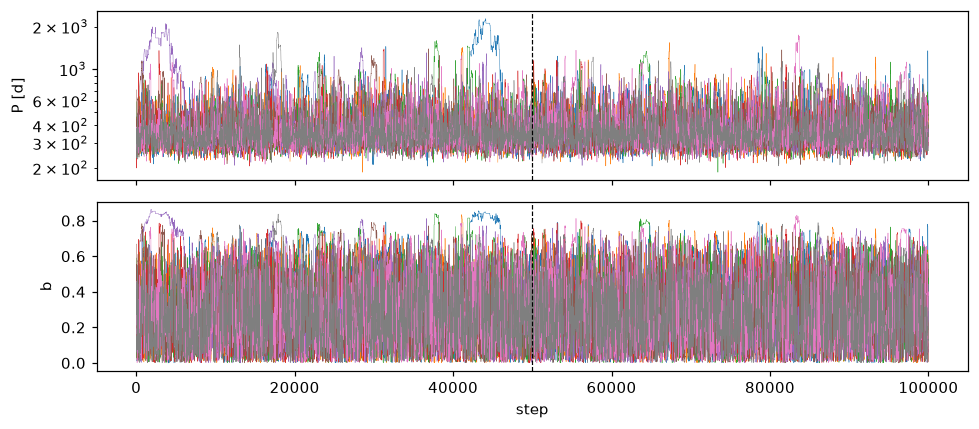

In [6]:
steps = (np.arange(chain.shape[0]) + 1) * THIN
fig, axes = plt.subplots(2, 1, figsize=(9, 4), sharex=True)
axes[0].plot(steps, period(chain[:, :8, 1], chain[:, :8, 6]), lw=0.3)
axes[0].set(yscale="log", ylabel="P [d]")
axes[1].plot(steps, chain[:, :8, 2], lw=0.3)
axes[1].set(ylabel="b", xlabel="step")
for ax in axes:
    ax.axvline(steps[chain.shape[0] // 2], color="k", ls="--", lw=0.8)
fig.tight_layout()

## Comparison with the authors' samples

Median, 68 % interval and two-sample KS distance $D$. Under the null, $D > 1.36\sqrt{1/n_1 + 1/n_2}$ in 5 % of
cases, with $n$ the number of independent samples (ours: samples · THIN / $\tau$; the authors' samples are taken
as independent – their lag-1 autocorrelation is printed as a check).

$M_*$ is a pure prior draw on our side, so its row only tests whether we use the same mass prior.

In [7]:
COLS = ["M", "rho", "t0", "P", "b", "r_R", "u1", "u2"]   # order of posteriors.csv
rng = np.random.default_rng(1)
ours = pd.DataFrame({c: q[c].ravel() for c in COLS[1:]})
ours.insert(0, "M", 10 ** rng.normal(*LOG_M, len(ours)))
authors = pd.read_csv("posteriors.csv", index_col=0)[COLS]
print(f"authors' samples: max |lag-1 autocorr| = {authors.apply(lambda c: c.autocorr()).abs().max():.3f}")

def interval(x):
    lo, med, hi = np.percentile(x, [15.865, 50, 84.135])
    return med, med - lo, hi - med

def fmt(med, lo, hi):
    d = max(0, 1 - int(np.floor(np.log10(min(lo, hi)))))   # 2 significant digits on the errors
    return f"{med:.{d}f} -{lo:.{d}f} +{hi:.{d}f}"

rows = {}
for c in COLS:
    n_ours = len(ours) if c == "M" else len(ours) * THIN / tau[c]
    rows[c] = {
        "ours": fmt(*interval(ours[c])),
        "authors": fmt(*interval(authors[c])),
        "KS D": stats.ks_2samp(ours[c], authors[c]).statistic,
        "5% limit": 1.36 * np.sqrt(1 / n_ours + 1 / len(authors)),
    }
display(pd.DataFrame(rows).T)

authors' samples: max |lag-1 autocorr| = 0.012


,ours,authors,KS D,5% limit
M,0.726 -0.017 +0.017,0.726 -0.016 +0.016,0.010044,0.006663
rho,2.85 -0.26 +0.28,2.86 -0.26 +0.28,0.006364,0.009053
t0,8055.0968 -0.0033 +0.0034,8055.0969 -0.0033 +0.0034,0.011112,0.00909
P,350 -57 +166,355 -59 +190,0.027224,0.019216
b,0.28 -0.20 +0.27,0.29 -0.21 +0.27,0.023292,0.015551
r_R,0.01365 -0.00041 +0.00054,0.01368 -0.00040 +0.00055,0.026296,0.016854
u1,0.560 -0.067 +0.067,0.559 -0.067 +0.067,0.006568,0.009226
u2,0.096 -0.070 +0.070,0.095 -0.070 +0.069,0.005264,0.009051


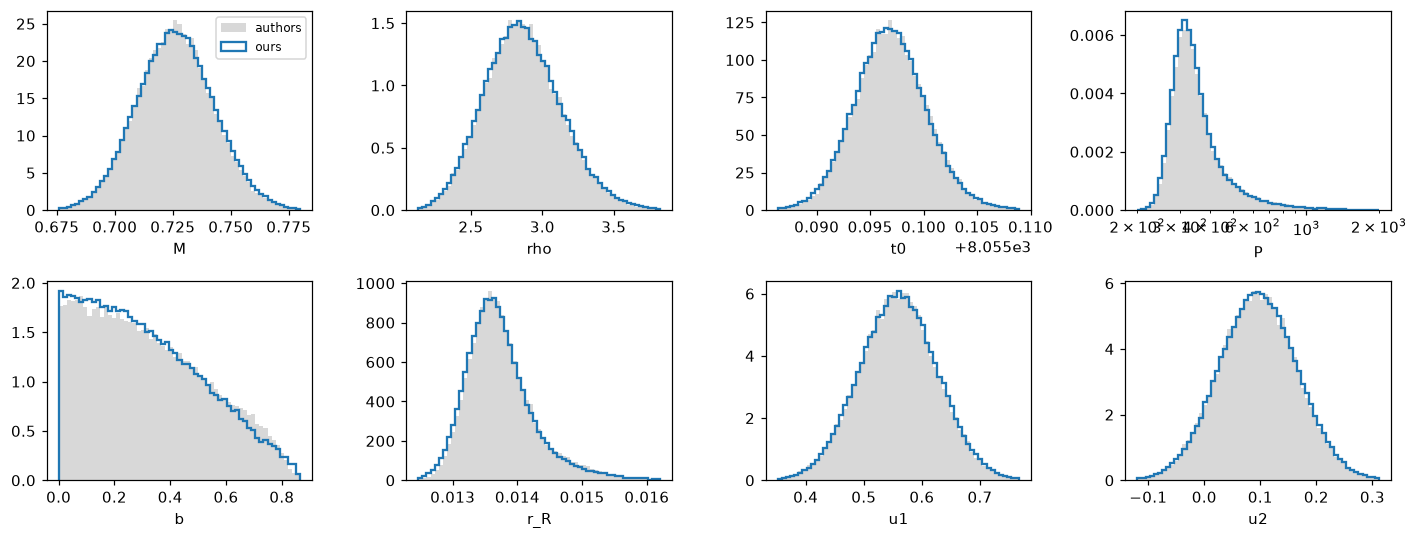

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(13, 5))
for ax, c in zip(axes.flat, COLS):
    if c == "P":
        bins = np.geomspace(200, 2000, 60)
        ax.set_xscale("log")
    else:
        bins = np.linspace(*np.percentile(np.r_[ours[c], authors[c]], [0.1, 99.9]), 60)
    ax.hist(authors[c], bins, density=True, histtype="stepfilled", alpha=0.3, color="gray", label="authors")
    ax.hist(ours[c], bins, density=True, histtype="step", lw=1.5, color="C0", label="ours")
    ax.set_xlabel(c)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()

## Derived quantities vs. Table 2

$R_* = (3M_*/4\pi\rho_*)^{1/3}$, $R_p = kR_*$, $a = (GM_*P^2/4\pi^2)^{1/3}$, $I/I_\oplus = (L_*/L_\odot)/(a/\mathrm{AU})^2$
with $L_* = 0.232 \pm 0.022\,L_\odot$. HZ limits from Sec. 4.2: conservative 0.30–1.00, optimistic 0.27–1.60 $I_\oplus$.

In [9]:
MSUN, REARTH, AU = 1.989e33, 6.371e8, 1.496e13

def derived(s):
    M = s["M"].values * MSUN
    R_star = (3 * M / (4 * np.pi * s["rho"].values)) ** (1 / 3)
    a = (G * M * (s["P"].values * DAY) ** 2 / (4 * np.pi**2)) ** (1 / 3)
    L = np.random.default_rng(2).normal(0.232, 0.022, len(s))
    return {"P [d]": s["P"].values, "Rp [R_earth]": s["r_R"].values * R_star / REARTH,
            "a [AU]": a / AU, "I [I_earth]": L / (a / AU) ** 2}

d_ours, d_auth = derived(ours), derived(authors)
table = pd.DataFrame({
    "paper (Table 2)": {"P [d]": "355 -59 +200", "Rp [R_earth]": "1.06 -0.05 +0.06",
                        "a [AU]": "0.88 -0.10 +0.32", "I [I_earth]": "0.29 -0.13 +0.11"},
    "authors' samples": {k: fmt(*interval(v)) for k, v in d_auth.items()},
    "ours": {k: fmt(*interval(v)) for k, v in d_ours.items()},
})
table.loc["b (3σ upper limit)"] = ["< 0.85"] + [f"< {np.percentile(s.b, 99.73):.2f}" for s in (authors, ours)]
for name, paper, (lo, hi) in [("Pr(HZ conservative)", "40% (text)", (0.30, 1.00)),
                              ("Pr(HZ optimistic)", "51% (text)", (0.27, 1.60))]:
    table.loc[name] = [paper] + [f"{np.mean((d['I [I_earth]'] > lo) & (d['I [I_earth]'] < hi)):.0%}"
                                 for d in (d_auth, d_ours)]
display(table)

,paper (Table 2),authors' samples,ours
P [d],355 -59 +200,355 -59 +190,350 -57 +166
Rp [R_earth],1.06 -0.05 +0.06,1.063 -0.047 +0.056,1.061 -0.048 +0.055
a [AU],0.88 -0.10 +0.32,0.88 -0.10 +0.29,0.874 -0.098 +0.257
I [I_earth],0.29 -0.13 +0.11,0.294 -0.128 +0.092,0.300 -0.121 +0.091
b (3σ upper limit),< 0.85,< 0.84,< 0.84
Pr(HZ conservative),40% (text),48%,50%
Pr(HZ optimistic),51% (text),59%,61%


## Conclusions

- $\rho_*$, $T_0$, $u_1$, $u_2$ agree with the authors within sampling noise.
- $P$, $b$, $k$ are close but not identical: our $P$ tail is shorter, $b$ and $k$ slightly narrower.
  The nested-sampling runs in 03 (Sec. 5) and 04 (Sec. 6) give the same posterior as this chain, which points to a difference in the
  setup (noise model, data window?) rather than the sampler.
- $M_*$ agrees with the paper's mass prior (a pure prior draw on both sides).
- HZ fractions from the authors' samples (48 % / 59 %) disagree with the paper text (40 % / 51 %).
- Open: residuals are correlated (PPC), so white noise is probably too simple.